In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import dask
import zarr
import xarray as xr
import sys
sys.path.insert(0, '/home/codycruz/LLC_ocean_emulator/high_res_diagnostics')
from predictions_io import open_predictions
import cftime
import os
import json
from scipy.spatial import cKDTree

In [ ]:
# ============== LOAD LLC ==============

# DOMAIN: face = int for one face, slice(0,13) for the globe (cache faces 7-12 are north-up, like the emulator)
face=1#slice(0,13)#1
x_extent=slice(150,100)
y_extent=slice(150,250)

# Coarse cache: normalized float16 channels (U_0..Salt_50, Eta), land 0 -> physical units, land NaN
cache = xr.open_zarr('/orcd/scratch/seedfund/001/llc_emulator/coarse/LLC4320_coarse_cache_0p33deg.zarr',
                     consolidated=False).drop_vars('boundary')
native = zarr.open_group(cache.attrs['native_store'], mode='r')
stats = {s: xr.DataArray(np.concatenate([native[f'{v}_{s}'][:] for v in ('U', 'V', 'Theta', 'Salt', 'Eta')]),
                         dims='channel') for s in ('mean', 'std')}
prog = (cache.prognostic * stats['std'] + stats['mean']).where(cache.wet.astype(bool))
llc_vars = {v: prog.isel(channel=slice(51 * n, 51 * (n + 1))).rename(channel='k').transpose('time', 'k', 'face', 'y', 'x')
            for n, v in enumerate(['U', 'V', 'Theta', 'Salt'])}
llc_vars['Eta'] = prog.isel(channel=204)

llc_patch_full_face = xr.Dataset({**llc_vars, 'XC': cache.XC, 'YC': cache.YC, 'rA': cache.rA}).assign_coords(
    face=np.arange(13), k=np.arange(51)
).isel(
    face=face,
    x=x_extent,
    y=y_extent
)

In [10]:
# x_extent=slice(180,225)
# y_extent=slice(45,90)

llc_patch_full = llc_patch_full_face.isel(
    x=x_extent,
    y=y_extent
)

# ============== LOAD EMULATORS ==============
emulator_configs = [
    {
        'name': 'w384-ckpt48',
        'key': 'emulator_1',
        'path': '/orcd/scratch/seedfund/001/llc_emulator/inference/coarse/w384-ckpt48/predictions.zarr',
        'desc': ''
    },
    {
        'name': 'w512-ckpt47',
        'key': 'emulator_2',
        'path': '/orcd/scratch/seedfund/001/llc_emulator/inference/coarse//w512-ckpt47/predictions.zarr',
        'desc': ''
    },
#     {
#         'name': 'band_h-ckpt4',
#         'key': 'emulator_3',
#         'path': '/orcd/scratch/seedfund/001/llc_emulator/inference/1face//epoch4-ema-quintic-band_h/predictions.zarr',
#         'desc': ''
#     },
#    {
#         'name': 'band_hz-ckpt4',
#         'key': 'emulator_4',
#         'path': '/orcd/scratch/seedfund/001/llc_emulator/inference/1face//epoch4-ema-quintic-band_hz/predictions.zarr',
#         'desc': ''
#     },
]

# ============== OPEN EMULATOR DATASETS ==============
emulator_patches_raw = {}
for cfg in emulator_configs:
    # Load emulator data
    emu_ds = open_predictions(cfg['path'])
    
    # Rename dimensions to match LLC if needed
    # (adjust these names based on your actual emulator dimension names)
    dim_mapping = {}
    if 'lat' in emu_ds.dims and 'y' not in emu_ds.dims:
        dim_mapping['lat'] = 'y'
    if 'lon' in emu_ds.dims and 'x' not in emu_ds.dims:
        dim_mapping['lon'] = 'x'
    
    if dim_mapping:
        emu_ds = emu_ds.rename(dim_mapping)
    
    # Apply same spatial slicing as LLC
    emu_ds = emu_ds.isel(face=face, x=x_extent, y=y_extent)
    
    # Align emulator to LLC's coordinates
    emu_ds = emu_ds.assign_coords({
        'x': llc_patch_full.x,
        'y': llc_patch_full.y
    })
    
    emulator_patches_raw[cfg['key']] = emu_ds
    print(f"Loaded {cfg['name']}: {cfg['desc']}")

# ============== TIME MATCHING ==============
def normalize_times(times):
    return pd.DatetimeIndex([
        pd.Timestamp(
            int(t.year), int(t.month), int(t.day),
            int(t.hour), int(t.minute), int(t.second)
        )
        if hasattr(t, "year")
        else pd.Timestamp(t).floor("s")
        for t in times
    ])

llc_times_norm = normalize_times(llc_patch_full.time.values)

common_times = llc_times_norm
for cfg in emulator_configs:
    emulator_times_norm = normalize_times(emulator_patches_raw[cfg['key']].time.values)
    common_times = common_times.intersection(emulator_times_norm)

common_times = common_times.sort_values()

llc_mask = llc_times_norm.isin(common_times)
llc_patch = llc_patch_full.isel(time=llc_mask)

print(f"LLC subset to {len(common_times)} common times")

# ============== PORT GRID VARS & BUILD UNIFIED STRUCTURE ==============
grid_vars = ['XC', 'YC', 'rA', 'Z', 'dxC', 'dyC', 'dxG', 'dyG']

emulator_patches = {}
for cfg in emulator_configs:
    patch_raw = emulator_patches_raw[cfg['key']]
    patch_times_norm = normalize_times(patch_raw.time.values)

    patch_mask = patch_times_norm.isin(common_times)
    patch = patch_raw.isel(time=patch_mask)

    # Add LLC grid variables
    for gv in grid_vars:
        if gv in llc_patch:
            patch[gv] = llc_patch[gv]

    emulator_patches[cfg['key']] = patch

# ============== UNIFIED REFERENCE LISTS ==============
emulator_info = [(cfg['name'], cfg['key']) for cfg in emulator_configs]
n_emulators = len(emulator_info)

all_patches = {'llc': llc_patch}
all_patches.update(emulator_patches)

print(f"\n=== Setup complete: LLC + {n_emulators} emulators ===")
for name, key in emulator_info:
    print(f"  {name} ({key})")
    print(f"    Shape: {emulator_patches[key][list(emulator_patches[key].data_vars)[0]].shape}")
    print(f"    x range: [{emulator_patches[key].x.values.min()}, {emulator_patches[key].x.values.max()}]")
    print(f"    y range: [{emulator_patches[key].y.values.min()}, {emulator_patches[key].y.values.max()}]")

print(f"LLC shape: {llc_patch[list(llc_patch.data_vars)[0]].shape}")

Loaded w384-ckpt48: 
Loaded w512-ckpt47: 
LLC subset to 744 common times

=== Setup complete: LLC + 2 emulators ===
  w384-ckpt48 (emulator_1)
    Shape: (744, 51, 270, 270)
    x range: [0, 269]
    y range: [0, 269]
  w512-ckpt47 (emulator_2)
    Shape: (744, 51, 270, 270)
    x range: [0, 269]
    y range: [0, 269]
LLC shape: (744, 51, 270, 270)


In [11]:
selected_time_range = [0, 744]   # inclusive indices
stepping = 1                    # 1 = every timestep, 4 = every 4th timestep

start_idx, end_idx = selected_time_range

# ----------------------------------------
# First subset LLC
# ----------------------------------------
llc_patch = llc_patch.isel(
    time=slice(start_idx, end_idx + 1, stepping)
)

# ----------------------------------------
# Then subset each emulator safely
# Handles shorter emulator runs automatically
# ----------------------------------------
emulator_patches_subset = {}

for key, patch in emulator_patches.items():

    max_time = patch.sizes['time']

    # Prevent indexing past emulator length
    safe_end_idx = min(end_idx, max_time - 1)

    patch_subset = patch.isel(
        time=slice(start_idx, safe_end_idx + 1, stepping)
    )

    emulator_patches_subset[key] = patch_subset

emulator_patches = emulator_patches_subset

# ----------------------------------------
# Match LLC length to shortest emulator
# ----------------------------------------
min_time_len = min(
    [llc_patch.sizes['time']] +
    [patch.sizes['time'] for patch in emulator_patches.values()]
)

llc_patch = llc_patch.isel(time=slice(0, min_time_len))

emulator_patches = {
    key: patch.isel(time=slice(0, min_time_len))
    for key, patch in emulator_patches.items()
}

# ----------------------------------------
# Rebuild combined dict
# ----------------------------------------
all_patches = {'llc': llc_patch}
all_patches.update(emulator_patches)

# ----------------------------------------
# Diagnostics
# ----------------------------------------
print(f"Subset to time indices {start_idx}:{end_idx}")
print(f"Stepping = {stepping}")
print(f"Final synchronized length = {min_time_len}")

print(f"LLC now has {llc_patch.sizes['time']} times")

for name, key in emulator_info:
    print(
        f"{name} ({key}) now has "
        f"{emulator_patches[key].sizes['time']} times"
    )

Subset to time indices 0:744
Stepping = 1
Final synchronized length = 744
LLC now has 744 times
w384-ckpt48 (emulator_1) now has 744 times
w512-ckpt47 (emulator_2) now has 744 times


In [12]:
def format_time(t_val):
    """Format a time value to DD/MM/YYYY:HH regardless of cftime or datetime64."""
    try:
        return f"{t_val.day:02d}/{t_val.month:02d}/{t_val.year}:{t_val.hour:02d}h"
    except AttributeError:
        t_pd = pd.Timestamp(t_val)
        return f"{t_pd.day:02d}/{t_pd.month:02d}/{t_pd.year}:{t_pd.hour:02d}h"
# ============== VERTICAL-AXIS HELPERS (W lives on cell interfaces) ==============
# LLC keeps W on `k_p1` -- 52 cell INTERFACES -- while Theta/Salt/U/V sit on `k`,
# 51 cell CENTRES. The emulator writes W back onto `k` with 51 levels. So a
# blanket `.isel(k=...)` silently leaves LLC's W at full depth (the level index
# never applies) and the plot then fails on a 3-D array, or a difference
# broadcasts 52 against 51. Level L means the same layer in both: the emulator's
# `k=L` is trained against LLC's `k_p1=L`.
VERTICAL_DIMS = ("k", "k_p1", "k_l", "k_u", "lev")


def vertical_dim_of(da):
    """Whichever vertical dimension this variable carries, or None if surface."""
    for dim in VERTICAL_DIMS:
        if dim in da.dims:
            return dim
    return None


def pick(patch, var, *, time=None, k=None):
    """`patch[var]` with `time`/`k` applied to the axes it actually has."""
    da = patch[var]
    if time is not None:
        da = da.isel(time=time)
    if k is not None:
        dim = vertical_dim_of(da)
        if dim is not None:
            da = da.isel({dim: k})
    return da


def common_levels(*patch_var_pairs):
    """Levels the given (patch, var) pairs share.

    LLC's W has 52 and the emulator's has 51, so depth comparisons have to trim
    to the shorter of the two rather than broadcast.
    """
    sizes = []
    for patch, var in patch_var_pairs:
        dim = vertical_dim_of(patch[var])
        sizes.append(patch[var].sizes[dim] if dim is not None else 1)
    return min(sizes)


def depth_axis(patch, var):
    """Depth in metres for each level of `var`, negative downward.

    The store carries `Z` for cell centres but no coordinate for the interfaces
    W sits on, so derive them: face[0] = 0, face[i+1] = 2*centre[i] - face[i].
    That is the same construction as DEPTH_INTERFACES in ocean_emulators.
    """
    centres = np.asarray(patch['Z'].values, dtype=float)
    if vertical_dim_of(patch[var]) != 'k_p1':
        return centres
    faces = [0.0]
    for centre in centres:
        faces.append(2.0 * centre - faces[-1])
    return np.asarray(faces)

In [ ]:
# ============== AR-STABILITY STATS ==============
VARS = ['Theta', 'Salt', 'U', 'V', 'Eta']
STATS = ['rmse']    # any of: mean std rmse
MODE = 'FULL'    # FULL (k x var grid) | COLUMN_MEAN_ONLY | SURFACE (k=0); the last two stack vars vertically
# ================================================
import time as _time
import warnings

DEPTH_AVERAGE = slice(0, 51, 5)  # column-mean levels
DEPTH_LEVELS = [10, 25, 50]      # extra single-level rows in FULL mode (k=0 is the 'surface' row)
TIME_BLOCK = 4                   # time steps read per pass (~1 GB per source on the globe)

ROW_KEYS = {'FULL': ['column', 'surface', *DEPTH_LEVELS], 'COLUMN_MEAN_ONLY': ['column'], 'SURFACE': ['surface']}[MODE]
_ALL_ROWS = {'column': list(range(*DEPTH_AVERAGE.indices(51))), 'surface': [0], **{k: [k] for k in DEPTH_LEVELS}}
ROWS = {r: _ALL_ROWS[r] for r in ROW_KEYS}
LEVELS_TO_READ = sorted({k for ks in ROWS.values() for k in ks})
ROW_POS = {r: [LEVELS_TO_READ.index(k) for k in ks] for r, ks in ROWS.items()}
SOURCES = [('llc', llc_patch)] + [(key, emulator_patches[key]) for _, key in emulator_info]
SP_NDIM = llc_patch['rA'].ndim  # (y, x) for one face, (face, y, x) for the globe
_rA = llc_patch['rA'].values.astype('f8').ravel()
AREA_W = _rA / _rA.sum()


def _read(patch, tsl):
    """All vars for one time block in one read (the cache stores every channel in one chunk); spatial dims flattened."""
    block = patch[VARS].isel(time=tsl, k=LEVELS_TO_READ).compute()
    return {v: block[v].values.astype('f8').reshape(*block[v].shape[:-SP_NDIM], -1) for v in VARS}


def _wstats(x, ok):
    """Area-weighted (mean, std, weight sum) over cells valid in `ok` and x. x: (nb, ncell)."""
    ok = ok & np.isfinite(x)
    w = np.where(ok, AREA_W, 0.0)
    wsum = w.sum(-1)
    with np.errstate(invalid='ignore', divide='ignore'):
        mean = (np.where(ok, x, 0.0) * w).sum(-1) / wsum
        var = (np.where(ok, x - mean[:, None], 0.0) ** 2 * w).sum(-1) / wsum
    return mean, np.sqrt(var), wsum


def _rms(d2):
    """sqrt of the area-weighted mean of a per-cell squared error."""
    ok = np.isfinite(d2)
    w = np.where(ok, AREA_W, 0.0)
    with np.errstate(invalid='ignore', divide='ignore'):
        return np.sqrt((np.where(ok, d2, 0.0) * w).sum(-1) / w.sum(-1))


def _dmean(a, pos):
    """Depth-average over `pos` (None = 2D var), ignoring NaN levels."""
    if pos is None:
        return a
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)
        return np.nanmean(a[:, pos], axis=1)


def _sq_err(x, truth, pos):
    """Per-cell squared error, squared per level before depth-averaging so opposite-sign errors cannot cancel."""
    return _dmean((x - truth) ** 2, pos)


N_T = llc_patch.sizes['time']
_tt = normalize_times(llc_patch.time.values)
STEPS = ((_tt - _tt[0]).total_seconds() / 3600.0).to_numpy()  # hours since rollout start
stats, truth0 = {}, {}


def _put(key, i0, vals):
    stats.setdefault(key, np.full(N_T, np.nan))[i0:i0 + len(vals)] = vals


_t0 = _time.time()
for i0 in range(0, N_T, TIME_BLOCK):
    tsl = slice(i0, min(i0 + TIME_BLOCK, N_T))
    blocks = {name: _read(patch, tsl) for name, patch in SOURCES}
    for var in VARS:
        truth = blocks['llc'][var]
        if i0 == 0:
            truth0[var] = truth[:1].copy()  # persistence forecast: hold the first truth state fixed
        rows = {ROW_KEYS[0]: None} if truth.ndim == 2 else ROW_POS
        for row, pos in rows.items():
            valid = np.isfinite(_dmean(truth, pos))
            for name, _ in SOURCES:
                x = blocks[name][var]
                mean, std, wsum = _wstats(_dmean(x, pos), valid)
                if name == 'llc':
                    truth_wsum = wsum
                _put(('valid_frac', var, row, name), i0, wsum / truth_wsum)
                if 'mean' in STATS:
                    _put(('mean', var, row, name), i0, mean)
                if 'std' in STATS:
                    _put(('std', var, row, name), i0, std)
                if 'rmse' in STATS and name != 'llc':
                    _put(('rmse', var, row, name), i0, _rms(_sq_err(x, truth, pos)))
            if 'rmse' in STATS:
                _put(('rmse', var, row, 'persistence'), i0, _rms(_sq_err(truth0[var], truth, pos)))
    del blocks
    print(f"  t[{tsl.start}:{tsl.stop}] of {N_T}  ({_time.time() - _t0:5.0f}s)", flush=True)

print(f"\ndone: {len(stats)} series of length {N_T} in {(_time.time() - _t0) / 60:.1f} min")
print("valid fraction of truth's ocean (1.000 = no NaN/inf anywhere):")
for var in VARS:
    for name, _ in SOURCES[1:]:
        v = stats[('valid_frac', var, ROW_KEYS[0], name)]
        print(f"    {var:6s} {name:12s} min {np.nanmin(v):.4f}" + ("" if np.nanmin(v) > 0.9999 else "   <-- NaN/inf present"))

  t[0:4] of 744  (    9s)
  t[4:8] of 744  (   17s)
  t[8:12] of 744  (   26s)
  t[12:16] of 744  (   34s)
  t[16:20] of 744  (   43s)
  t[20:24] of 744  (   51s)
  t[24:28] of 744  (   59s)
  t[28:32] of 744  (   67s)
  t[32:36] of 744  (   75s)
  t[36:40] of 744  (   84s)
  t[40:44] of 744  (   92s)
  t[44:48] of 744  (  100s)
  t[48:52] of 744  (  108s)
  t[52:56] of 744  (  116s)
  t[56:60] of 744  (  130s)
  t[60:64] of 744  (  151s)
  t[64:68] of 744  (  167s)
  t[68:72] of 744  (  183s)
  t[72:76] of 744  (  199s)
  t[76:80] of 744  (  215s)
  t[80:84] of 744  (  229s)
  t[84:88] of 744  (  247s)
  t[88:92] of 744  (  263s)
  t[92:96] of 744  (  278s)
  t[96:100] of 744  (  293s)
  t[100:104] of 744  (  309s)
  t[104:108] of 744  (  324s)
  t[108:112] of 744  (  340s)
  t[112:116] of 744  (  357s)
  t[116:120] of 744  (  372s)
  t[120:124] of 744  (  388s)
  t[124:128] of 744  (  404s)
  t[128:132] of 744  (  422s)
  t[132:136] of 744  (  447s)
  t[136:140] of 744  (  464s)
  t[

findfont: Font family ['STIXGeneral'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXGeneral'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXGeneral'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXGeneral'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXNonUnicode'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXNonUnicode'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXNonUnicode'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXSizeOneSym'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXSizeTwoSym'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXSizeThreeSym'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXSizeFourSym'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXSizeFiveSym'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmsy10'] not

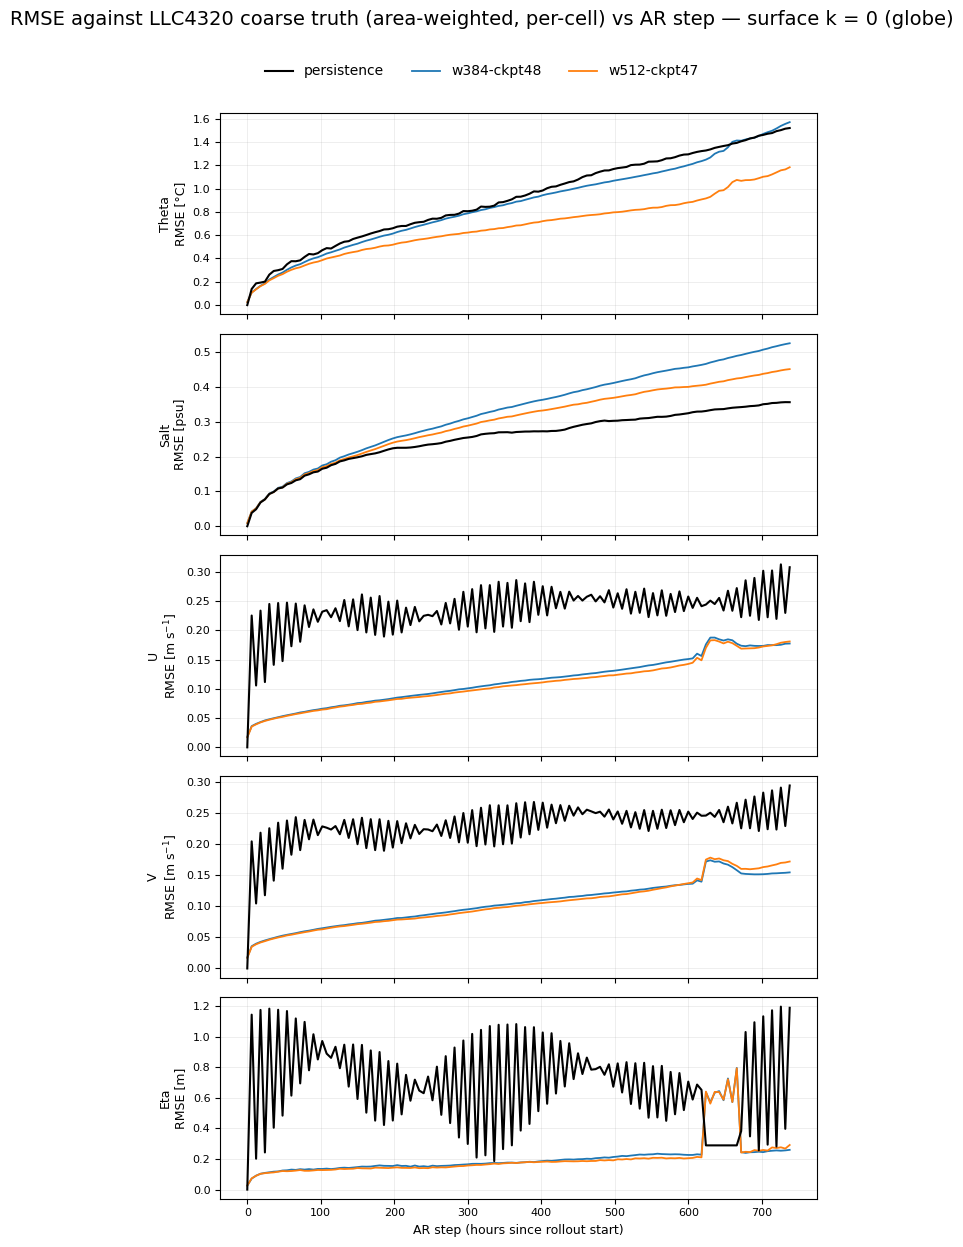

saved figs/AR-stability/globe/AR-stability_rmse_surface.png


In [ ]:
# ============== PLOTTER (plots the VARS / STATS / MODE computed above) ==============

UNITS = {'Theta': '°C', 'Salt': 'psu', 'U': 'm s$^{-1}$', 'V': 'm s$^{-1}$', 'Eta': 'm'}
ROW_LABELS = {'column': f"column mean\nk[{DEPTH_AVERAGE.start}:{DEPTH_AVERAGE.stop}:{DEPTH_AVERAGE.step}]",
              'surface': 'surface\nk = 0', **{k: f'k = {k}' for k in DEPTH_LEVELS}}
LINE_STYLE = {'llc': dict(color='k', lw=2.0, zorder=5), 'persistence': dict(color='k', lw=1.5, zorder=4)}
_PALETTE = plt.rcParams['axes.prop_cycle'].by_key()['color']
for _i, (_n, _k) in enumerate(emulator_info):
    LINE_STYLE[_k] = dict(color=_PALETTE[_i % len(_PALETTE)], lw=1.3)
LABEL = {'llc': 'LLC4320 coarse (truth)', 'persistence': 'persistence', **{k: n for n, k in emulator_info}}
FIGURES = {
    'mean': ('Domain-mean (area-weighted by rA) vs AR step', 'AR-stability_domain-mean', 'mean [{u}]'),
    'std': ('Domain standard deviation (area-weighted) vs AR step', 'AR-stability_domain-std', 'std [{u}]'),
    'rmse': ('RMSE against LLC4320 coarse truth (area-weighted, per-cell) vs AR step', 'AR-stability_rmse', 'RMSE [{u}]'),
}
tag = 'globe' if 'face' in llc_patch.dims else f'face{face}'
OUT_DIR = f'figs/AR-stability/{tag}'
os.makedirs(OUT_DIR, exist_ok=True)


def plot_stat(stat, title, fname, ylabel_fmt):
    """Time series of `stat`: a row x var grid (FULL), or vars stacked vertically (COLUMN_MEAN_ONLY / SURFACE)."""
    names = ['persistence'] + [k for _, k in emulator_info] if stat == 'rmse' else [n for n, _ in SOURCES]
    rows = ROW_KEYS
    stacked = MODE != 'FULL'
    # (grid row, grid col, var, row key) per panel; 2D vars (Eta) only fill the first row
    if stacked:
        panels = [(c, 0, var, rows[0]) for c, var in enumerate(VARS)]
        nr, nc, size = len(VARS), 1, (7.0, 2.4 * len(VARS))
    else:
        panels = [(r, c, var, row) for r, row in enumerate(rows) for c, var in enumerate(VARS)
                  if r == 0 or 'k' in llc_patch[var].dims]
        nr, nc, size = len(rows), len(VARS), (4.2 * len(VARS), 2.7 * len(rows))
    last_row = {}  # lowest grid row with content per grid column
    for gr, gc, _, _ in panels:
        last_row[gc] = max(last_row.get(gc, -1), gr)

    fig, axes = plt.subplots(nr, nc, figsize=size, squeeze=False, sharex=True)
    for ax in axes.flat:
        ax.axis('off')
    for gr, gc, var, row in panels:
        ax = axes[gr][gc]
        ax.axis('on')
        for name in names:
            ax.plot(STEPS, stats[(stat, var, row, name)], label=LABEL[name], **LINE_STYLE[name])
        ylab = ylabel_fmt.format(u=UNITS[var])
        if stacked:
            ax.set_ylabel(f"{var}\n{ylab}", fontsize=9)
        else:
            if gr == 0:
                ax.set_title(var, fontsize=12, fontweight='bold')
            ax.set_ylabel(f"{ROW_LABELS[row]}\n{ylab}" if gc == 0 else ylab, fontsize=9)
        if gr == last_row[gc]:
            ax.set_xlabel('AR step (hours since rollout start)', fontsize=9)
        ax.grid(alpha=0.3, lw=0.5)
        ax.tick_params(labelsize=8)
    handles, labels = axes[panels[0][0]][panels[0][1]].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', ncol=len(labels), bbox_to_anchor=(0.5, 1.0), frameon=False, fontsize=10)
    if stacked:
        title += f" — {ROW_LABELS[rows[0]].replace(chr(10), ' ')}"
        fname += '_column-mean' if MODE == 'COLUMN_MEAN_ONLY' else '_surface'
    fig.suptitle(f'{title} ({tag})', fontsize=14, y=1.035)
    fig.tight_layout(rect=[0, 0, 1, 0.99])
    out = f"{OUT_DIR}/{fname}.png"
    fig.savefig(out, dpi=140, bbox_inches='tight')
    plt.show()
    print(f"saved {out}")


for _s in STATS:
    plot_stat(_s, *FIGURES[_s])